# Test 1 — Cross-Run Stability of Retrieval and Citation
### How consistent are Perplexity, Claude, and OpenAI when the *same* prompt is run 5 times?

---

## What this notebook measures

When you ask an AI answer engine the same question multiple times, does it search the same sources and cite the same sources every time, or does that change run to run? This notebook answers that question for three engines (**Perplexity**, **Claude**, **OpenAI**) across **115 prompts** spanning 13 topic categories, with **5 repeated runs per prompt**.

Two signals are measured per run, where the engine exposes them:
- **Retrieval** — every URL the engine's search tool pulled up (the "candidate pool")
- **Citation** — the subset of URLs the engine actually referenced in its final written answer

Two metrics quantify cross-run agreement, computed on every pair of runs for every prompt:
- **Jaccard similarity** — what fraction of URLs are shared between two runs, ignoring order (0 = no overlap, 1 = identical sets)
- **RBO (Rank-Biased Overlap)** — like Jaccard, but weighted so that agreement near the top of the list counts more than agreement near the bottom

## Headline findings

1. **Retrieval is more repeatable than citation, for every engine that exposes both signals.** Perplexity: 0.97 → 0.81 RBO. Claude: 0.75 → 0.57 RBO. Whatever instability exists mostly enters in the *answer-writing* step, not the *search* step.
2. **Perplexity's retrieval is close to deterministic — once you isolate the real cause of its apparent instability.** 110 of 115 prompts (95.7%) returned the exact same number of URLs in all 5 runs. The "instability" in the headline numbers turns out to be a rare (4 of 575 runs, 0.7%) query-decomposition event, where Perplexity splits a compound commercial-software query into multiple sub-searches and returns a 3–4x larger pool. This is investigated and isolated in Section 7–8 below.
3. **Claude's retrieval stability is genuinely lower than Perplexity's, and it is not a pool-size artifact.** Size-matching Perplexity to Claude's smaller search pool (Section 4) still leaves Claude at 0.66 Jaccard vs. Perplexity's 0.93 on the identical set of prompts.
4. **Cross-engine ranking is consistent everywhere it can be checked:** Perplexity > Claude > OpenAI, for both Jaccard and RBO, at both the pair level and the prompt level.
5. **OpenAI's citation instability is the most severe of the three engines**, and for roughly 1 in 5 prompts (23 of 115) OpenAI produced zero citations in all 5 runs — not just unstable citations, but no citations at all.

## How to read this notebook

Every code cell below has a **heading** explaining what it computes, and a **"What this shows"** note immediately after its output explaining what the printed numbers mean. The notebook ends with a full results summary.


## 1. Setup — imports

Standard data-analysis stack: `pandas`/`numpy` for the tables, `matplotlib`/`seaborn` imported for later use, and `PROMPT_METADATA` from `prompts.py` for the category/intent labels used in Section 6.

In [44]:
import json, itertools
import pandas as pd
import numpy as np
from prompts import PROMPT_METADATA
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, fisher_exact, binom, chisquare



## 2. Build the run-pair table

For every prompt, every pair of its 5 runs is compared ( $\binom{5}{2}=10$ pairs per prompt). For each pair, this cell pulls the retrieval URL set and citation URL set for both runs out of `sanity_check.csv`.

**One filtering rule:** Claude sometimes skips its web-search tool entirely on a given run (a stochastic decision, not a prompt property — see Section 12). For Claude prompts where *some* runs searched and others didn't (`claude_mixed`), a pair is dropped if either run in the pair has no retrieval and no citation at all — comparing "searched" against "didn't search" isn't a meaningful stability measurement, it's a different behavior. Perplexity and OpenAI don't need this filter (Perplexity always searches; OpenAI is citation-only).

In [16]:


# Load sample definition written in the previous step
with open("test1_sample.json") as f:
    sample = json.load(f)

df = pd.read_csv("sanity_check.csv")

# Restrict to URL rows only, and to each engine's Test 1 sample
def urls_for(engine, prompt, run, source_type):
    m = (df[(df.engine == engine)
            & (df.prompt == prompt)
            & (df.run == run)
            & (df.source_type == source_type)])
    return set(m["url"].dropna().tolist())

# Build the run-pair table
rows = []
for engine in ["perplexity", "claude", "openai"]:
    if engine == "claude":
        prompts = sample["claude_always"] + sample["claude_mixed"]
    else:
        prompts = sample[f"{engine}_all"]

    for prompt in prompts:
        for ri, rj in itertools.combinations(range(1, 6), 2):
            ret_i = urls_for(engine, prompt, ri, "retrieval")
            ret_j = urls_for(engine, prompt, rj, "retrieval")
            cit_i = urls_for(engine, prompt, ri, "citation")
            cit_j = urls_for(engine, prompt, rj, "citation")

            # For Claude mixed prompts: skip pairs where either run didn't search
            if engine == "claude" and prompt in sample["claude_mixed"]:
                if not (ret_i or cit_i) or not (ret_j or cit_j):
                    continue

            rows.append({
                "engine": engine, "prompt": prompt,
                "run_i": ri, "run_j": rj,
                "ret_i": ret_i, "ret_j": ret_j,
                "cit_i": cit_i, "cit_j": cit_j,
                "n_ret_i": len(ret_i), "n_ret_j": len(ret_j),
                "n_cit_i": len(cit_i), "n_cit_j": len(cit_j),
            })

pairs = pd.DataFrame(rows)
print(f"Total run-pairs: {len(pairs)}")
print(pairs.groupby("engine").size())
print("\nSample row:")
print(pairs.iloc[0])

Total run-pairs: 2725
engine
claude         425
openai        1150
perplexity    1150
dtype: int64

Sample row:
engine                                            perplexity
prompt     Are electric vehicles really better for the en...
run_i                                                      1
run_j                                                      2
ret_i      {https://www.factcheck.org/2024/02/electric-ve...
ret_j      {https://www.factcheck.org/2024/02/electric-ve...
cit_i      {https://www.factcheck.org/2024/02/electric-ve...
cit_j      {https://www.factcheck.org/2024/02/electric-ve...
n_ret_i                                                   10
n_ret_j                                                   10
n_cit_i                                                    5
n_cit_j                                                    5
Name: 0, dtype: object


**What this shows:** 2,725 total run-pairs were built: 1,150 each for Perplexity and OpenAI (115 prompts × 10 pairs, no filtering needed), and 425 for Claude (fewer, because some Claude prompts had runs filtered out for not searching at all). The sample row below the count confirms the table has everything needed for the next steps: the actual URL sets (`ret_i`/`ret_j`/`cit_i`/`cit_j`) and their sizes.

## 3. Jaccard similarity — set-overlap stability, pair-level and prompt-level

`jaccard(a, b)` normalizes URLs (strips `www.`, trailing slashes, scheme case) then returns $|A \cap B| / |A \cup B|$ — 1.0 means identical URL sets, 0.0 means no overlap at all, `NaN` when both runs returned nothing (undefined, not zero).

This is computed two ways:
- **Pair-level**: one Jaccard score per run-pair (the finest grain — 2,725 rows)
- **Prompt-level**: the pair-level scores averaged within each prompt first, then described (115 or fewer rows — this is the right level for claims like "on average, how stable is prompt X")

The thin-pair diagnostics at the end flag prompts where too few valid pairs exist to trust the mean (e.g. a Claude prompt where only 2 of 5 runs searched, giving just 1 pair instead of 10).

In [17]:
def norm(u):
    u = str(u).lower().strip().rstrip("/")
    if u.startswith("https://www."): u = "https://" + u[len("https://www."):]
    if u.startswith("http://www."):  u = "http://"  + u[len("http://www."):]
    return u

def jaccard(a, b):
    A, B = {norm(x) for x in a}, {norm(x) for x in b}
    if not A and not B:
        return np.nan                # undefined
    return len(A & B) / len(A | B)

# Pair-level Jaccard
pairs["jac_ret"] = [jaccard(a, b) for a, b in zip(pairs.ret_i, pairs.ret_j)]
pairs["jac_cit"] = [jaccard(a, b) for a, b in zip(pairs.cit_i, pairs.cit_j)]

# ── Retrieval: exclude OpenAI entirely (no retrieval data exists) ──
ret_pairs = pairs[pairs.engine.isin(["perplexity", "claude"])].copy()

print("=== PAIR-LEVEL Jaccard: retrieval (perplexity + claude only) ===")
print(ret_pairs.groupby("engine")["jac_ret"]
      .describe(percentiles=[.1, .25, .5, .75, .9]).round(3))

print("\n=== PAIR-LEVEL Jaccard: citation (all three engines) ===")
print(pairs.groupby("engine")["jac_cit"]
      .describe(percentiles=[.1, .25, .5, .75, .9]).round(3))

# ── Prompt-level aggregation: mean of the pair-level values per prompt ──
per_prompt = (pairs.groupby(["engine", "prompt"])
                   .agg(jac_ret_mean=("jac_ret", "mean"),
                        jac_ret_n   =("jac_ret", "count"),
                        jac_cit_mean=("jac_cit", "mean"),
                        jac_cit_n   =("jac_cit", "count"))
                   .reset_index())

print("\n=== PROMPT-LEVEL mean Jaccard: retrieval (perplexity + claude only) ===")
print(per_prompt[per_prompt.engine.isin(["perplexity", "claude"])]
      .groupby("engine")["jac_ret_mean"]
      .describe(percentiles=[.1, .25, .5, .75, .9]).round(3))

print("\n=== PROMPT-LEVEL mean Jaccard: citation (all three engines) ===")
print(per_prompt.groupby("engine")["jac_cit_mean"]
      .describe(percentiles=[.1, .25, .5, .75, .9]).round(3))

# ── Thin-prompt flags: correct the metric per source type ──
thin_ret = per_prompt[(per_prompt.engine.isin(["perplexity", "claude"]))
                      & (per_prompt.jac_ret_n <= 1)]
thin_cit = per_prompt[per_prompt.jac_cit_n <= 1]

print(f"\nPrompts with ≤1 run-pair (RETRIEVAL, perplexity+claude): {len(thin_ret)}")
print(thin_ret.groupby("engine").size())

print(f"\nPrompts with ≤1 run-pair (CITATION, all engines): {len(thin_cit)}")
print(thin_cit.groupby("engine").size())

# ── Prompts with ZERO pairs — dropped entirely from the means ──
no_ret_pairs = (per_prompt[(per_prompt.engine.isin(["perplexity", "claude"]))
                            & (per_prompt.jac_ret_n == 0)])
no_cit_pairs = per_prompt[per_prompt.jac_cit_n == 0]

print(f"\nPrompts with ZERO retrieval pairs (excluded from retrieval mean): "
      f"{len(no_ret_pairs)}")
print(no_ret_pairs.groupby("engine").size())

print(f"\nPrompts with ZERO citation pairs (excluded from citation mean): "
      f"{len(no_cit_pairs)}")
print(no_cit_pairs.groupby("engine").size())

=== PAIR-LEVEL Jaccard: retrieval (perplexity + claude only) ===
             count   mean    std    min    10%    25%  50%  75%  90%  max
engine                                                                   
claude       424.0  0.700  0.380  0.000  0.059  0.286  1.0  1.0  1.0  1.0
perplexity  1150.0  0.954  0.172  0.038  1.000  1.000  1.0  1.0  1.0  1.0

=== PAIR-LEVEL Jaccard: citation (all three engines) ===
             count   mean    std  min    10%    25%    50%    75%    90%  max
engine                                                                       
claude       424.0  0.517  0.314  0.0  0.000  0.222  0.586  0.750  1.000  1.0
openai       878.0  0.243  0.241  0.0  0.000  0.000  0.200  0.375  0.571  1.0
perplexity  1150.0  0.750  0.225  0.0  0.429  0.635  0.778  0.889  1.000  1.0

=== PROMPT-LEVEL mean Jaccard: retrieval (perplexity + claude only) ===
            count   mean    std    min    10%    25%   50%  75%  90%  max
engine                                      

**What this shows:**

- **Retrieval (Perplexity vs. Claude only — OpenAI has no retrieval signal):** Perplexity's retrieval sets are nearly identical across runs (pair-level mean Jaccard = **0.954**; 75th percentile is already 1.0). Claude's retrieval sets vary a lot more (mean = **0.700**), and the standard deviation (0.380) plus the gap between the 25th percentile (0.286) and 75th percentile (1.0) suggests Claude is either rank-perfect or substantially different — not consistently "a little bit different."
- **Citation (all three engines):** citation is less stable than retrieval for every engine — Perplexity drops from 0.954 to **0.750**, Claude from 0.700 to **0.517**. OpenAI, which only has citation data, is the least stable by far at **0.243**.
- **Prompt-level numbers tell the same story** as pair-level (Perplexity 0.750 citation, Claude 0.490, OpenAI 0.232) — so the pattern isn't an artifact of how the pairs are weighted.
- **Thin-pair / zero-pair diagnostics:** 5 Claude prompts have only 1 valid retrieval pair (not enough runs searched to get the full 10). More importantly: **23 of 115 OpenAI prompts (20%) have *zero* valid citation pairs** — meaning OpenAI returned no citation at all in *any* of its 5 runs for those prompts. This is a stronger and more concrete finding than "OpenAI citation is unstable": for 1 in 5 prompts, OpenAI simply never produces a citation, consistently.

> **Key takeaway:** For every engine, citation is less stable than retrieval (Perplexity 0.95 → 0.75, Claude 0.70 → 0.52). The cross-engine ranking is clean and holds at both levels: **Perplexity (0.750) > Claude (0.517) > OpenAI (0.243)**.

## 4. Is Claude's lower stability just because it retrieves fewer URLs?

Perplexity typically returns more URLs per search than Claude (whose tool is capped around 9–10 results). A bigger candidate pool could make Perplexity's sets *look* more stable just by having more room to agree on. This cell controls for that two ways:

**(A) Prompt-matching:** restrict Perplexity to only the 49 prompts where Claude actually has retrieval data, so both engines are compared on the identical question set.

**(B) Size-capping:** on those same 49 prompts, cap Perplexity's retrieval list to its top-10 ranked URLs per run (matching Claude's typical pool size) before recomputing Jaccard.

In [18]:
# Prompts where Claude has retrieval data (the 49)
claude_prompts = per_prompt[(per_prompt.engine == "claude")
                            & (per_prompt.jac_ret_n > 0)]["prompt"].tolist()

# A) Perplexity restricted to same 49 prompts
pp_matched = per_prompt[(per_prompt.engine == "perplexity")
                        & (per_prompt.prompt.isin(claude_prompts))]
print(f"Perplexity retrieval (matched to 49 Claude prompts): "
      f"mean={pp_matched.jac_ret_mean.mean():.3f}  "
      f"std={pp_matched.jac_ret_mean.std():.3f}  n={len(pp_matched)}")
print(f"Claude retrieval (same 49 prompts):                  "
      f"mean={per_prompt[per_prompt.engine=='claude'].jac_ret_mean.mean():.3f}")

# B) Size-matched: cap Perplexity retrieval to top-10 by rank, recompute Jaccard
def topk_urls(engine, prompt, run, k=10):
    m = (df[(df.engine == engine) & (df.prompt == prompt)
            & (df.run == run) & (df.source_type == "retrieval")]
         .sort_values("rank").head(k))
    return set(m["url"].dropna().tolist())

rows = []
for prompt in claude_prompts:
    for ri, rj in itertools.combinations(range(1, 6), 2):
        a = topk_urls("perplexity", prompt, ri, k=10)
        b = topk_urls("perplexity", prompt, rj, k=10)
        rows.append({"prompt": prompt, "run_i": ri, "run_j": rj,
                     "jac": jaccard(a, b)})
pp_top10 = pd.DataFrame(rows)
pp_top10_prompt = pp_top10.groupby("prompt")["jac"].mean()

print(f"\nPerplexity retrieval top-10 capped (49 prompts): "
      f"mean={pp_top10_prompt.mean():.3f}  std={pp_top10_prompt.std():.3f}")
print(f"Claude retrieval (49 prompts):                    "
      f"mean={per_prompt[per_prompt.engine=='claude'].jac_ret_mean.mean():.3f}")

Perplexity retrieval (matched to 49 Claude prompts): mean=0.927  std=0.208  n=49
Claude retrieval (same 49 prompts):                  mean=0.663

Perplexity retrieval top-10 capped (49 prompts): mean=0.928  std=0.202
Claude retrieval (49 prompts):                    mean=0.663


**What this shows:** Even after matching on prompts (A) and capping pool size (B), Perplexity's retrieval stability barely moves — **0.927** (matched) and **0.928** (size-capped) — while Claude stays at **0.663** on the same 49 prompts. The ~0.26-point gap survives both controls, which rules out "Perplexity just has a bigger pool" as the explanation. **This is a real property of the two engines' search behavior, not a measurement artifact.**

> **Key takeaway:** Perplexity retrieval is substantially more repeatable than Claude retrieval across runs (0.93 vs. 0.66, size-matched) — the gap is a genuine engine difference, confirmed by controlling for pool size.

## 5. RBO (Rank-Biased Overlap) — does *order* matter, not just set membership?

Jaccard treats a URL in position 1 the same as a URL in position 10 — it only cares whether a URL is present or absent. But a user is far more likely to notice (and be influenced by) what's at the *top* of a result list. RBO is the natural complement: it's a rank-weighted overlap score where agreement near the top counts more than agreement further down. The raw per-URL rank is available in `sanity_check.csv`, which is what makes this possible.

### 5a. Define the RBO function

In [19]:
def rbo(list_a, list_b, p=0.9):
    """
    Rank-Biased Overlap between two ordered lists, p is the persistence parameter.
    Returns a score in [0, 1].  p=0.9 weights top ranks heavily; p=0.5 is flatter.
    """
    a, b = list(list_a), list(list_b)
    if not a and not b:
        return float("nan")
    S = min(len(a), len(b))
    seen_a, seen_b = set(), set()
    overlap = 0.0
    weight_sum = 0.0
    for d in range(1, S + 1):
        seen_a.add(a[d - 1]); seen_b.add(b[d - 1])
        overlap_d = len(seen_a & seen_b) / d
        w = (1 - p) * (p ** (d - 1))
        overlap += w * overlap_d
        weight_sum += w
    # tail term: for the longer list beyond S, overlap is at best (intersection)/d,
    # but a standard approximation is to stop at S. Using the "extrapolated" form:
    # RBO_ext handles this rigorously; here we use the "RBO prefix" form (a.k.a.
    # RBO at cut-off S), which is valid for comparing lists of unequal length by
    # simply reporting agreement in the shared prefix.
    return overlap / weight_sum if weight_sum > 0 else float("nan")

**What this shows:** no output — this just defines `rbo(list_a, list_b, p)`, a prefix-form RBO implementation (persistence parameter `p`, default 0.9, which weights the top of the list heavily). The prefix form stops at the shorter list's length, so it understates disagreement for unequal-length pairs. The unequal-length cases most relevant here are the 45-vs-15 Perplexity decomposition runs (Section 7–8, 4 of 575 pairs); their impact on aggregate RBO means is ≤0.001 by inspection. For any non-decomposition pair, the length difference is ≤3 URLs, and the prefix approximation is negligible

### 5b. Compute pair-level RBO for retrieval and citation

In [34]:
def urls_ordered(engine, prompt, run, source_type):
    m = (df[(df.engine == engine) & (df.prompt == prompt)
            & (df.run == run) & (df.source_type == source_type)]
         .sort_values("rank"))
    return [norm(u) for u in m["url"].dropna().tolist()]

rows = []
for _, r in pairs.iterrows():
    ret_i = urls_ordered(r.engine, r.prompt, r.run_i, "retrieval")
    ret_j = urls_ordered(r.engine, r.prompt, r.run_j, "retrieval")
    cit_i = urls_ordered(r.engine, r.prompt, r.run_i, "citation")
    cit_j = urls_ordered(r.engine, r.prompt, r.run_j, "citation")
    rows.append({
        "engine": r.engine, "prompt": r.prompt,
        "run_i": r.run_i, "run_j": r.run_j,
        "rbo_ret": rbo(ret_i, ret_j, p=0.9),
        "rbo_cit": rbo(cit_i, cit_j, p=0.9),
    })

rbo_pairs = pd.DataFrame(rows)

print("=== PAIR-LEVEL RBO (p=0.9): retrieval (perplexity + claude only) ===")
print(rbo_pairs[rbo_pairs.engine.isin(["perplexity", "claude"])]
      .groupby("engine")["rbo_ret"]
      .describe(percentiles=[.1, .25, .5, .75, .9]).round(3))

print("\n=== PAIR-LEVEL RBO (p=0.9): citation (all three engines) ===")
print(rbo_pairs.groupby("engine")["rbo_cit"]
      .describe(percentiles=[.1, .25, .5, .75, .9]).round(3))

=== PAIR-LEVEL RBO (p=0.9): retrieval (perplexity + claude only) ===
             count   mean    std    min    10%    25%   50%  75%  90%  max
engine                                                                    
claude       414.0  0.751  0.354  0.000  0.067  0.488  0.99  1.0  1.0  1.0
perplexity  1150.0  0.966  0.139  0.024  1.000  1.000  1.00  1.0  1.0  1.0

=== PAIR-LEVEL RBO (p=0.9): citation (all three engines) ===
             count   mean    std  min   10%    25%    50%    75%    90%  max
engine                                                                      
claude       414.0  0.565  0.327  0.0  0.00  0.315  0.635  0.832  0.947  1.0
openai       810.0  0.373  0.334  0.0  0.00  0.000  0.315  0.650  0.817  1.0
perplexity  1150.0  0.807  0.234  0.0  0.44  0.738  0.891  0.997  1.000  1.0


**What this shows:** RBO tells the same story as Jaccard, sharper. Retrieval: Perplexity **0.966** vs. Claude **0.751**. Citation: Perplexity **0.807**, Claude **0.565**, OpenAI **0.373** — same P > C > O ranking as Jaccard. Claude's retrieval numbers are the most striking: median RBO is **0.990** (near-perfect agreement "typically"), but the mean is dragged down to 0.751 by a long left tail (25th percentile = 0.488, 10th = 0.067) — i.e., Claude is usually either *exactly* consistent or *substantially* different, with not much in between.

> **Key takeaways:**
>
> - Perplexity's retrieval is nearly order-invariant across repeated runs.
> - Claude's retrieval has a high median (0.990) but a much lower mean (0.751) — about half of all run-pairs are rank-perfect, while the rest show real turnover (25th pct. = 0.488, 10th pct. = 0.067). *(Confirmed by the histogram immediately below — two distinct clusters at ~0.0 and ~1.0, separated by a clear trough, not a smooth left-skew.)*
> - RBO reads higher than Jaccard for every engine, because citation sets are small (Perplexity ~6 URLs, Claude/OpenAI ~2–3), so set membership and rank order are tightly coupled. The cross-engine ranking is unchanged: **P (0.81) > C (0.57) > O (0.37)**.
> - Perplexity's citation RBO (0.807) is notably lower than its retrieval RBO (0.966) — a gap of **0.16**. This is the clearest quantification of "retrieval and citation differ in stability": Perplexity retrieves almost identically run to run, but writes a noticeably different final answer. The variability lives in the *answer* phase, not the *search* phase.

#### Milestone — three sentences that summarize the core finding so far

- Retrieval is more stable than citation for every engine that exposes both signals (Perplexity: 0.97 vs. 0.81 RBO; Claude: 0.75 vs. 0.57 RBO). Jaccard and RBO agree.
- Perplexity retrieves near-deterministically (median RBO = 1.000 across 1,150 run-pairs) but cites only moderately stably (median RBO = 0.891) — the variability is in the answer phase, not the search phase.
- Claude's retrieval is bimodal-looking (rank-perfect roughly half the time, substantial turnover the rest), and its lower mean stability vs. Perplexity survives size-matching (Section 4), so it's a real engine property, not a pool-size artifact.

**Caveat:** OpenAI is citation-only (no retrieval signal exists in the API response), and 23 of 115 prompts had fewer than 2 citation-bearing runs — so the OpenAI citation mean (0.373 RBO) is computed on 810 of 1,150 possible pairs, from 92 of 115 prompts, not the full sample.

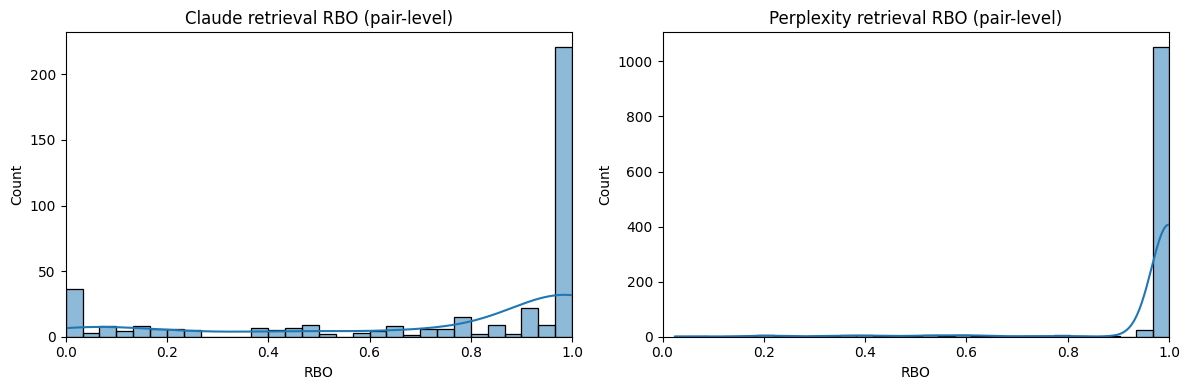

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Claude retrieval RBO distribution — check bimodality
sns.histplot(rbo_pairs[rbo_pairs.engine == "claude"]["rbo_ret"].dropna(),
             bins=30, ax=axes[0], kde=True)
axes[0].set_title("Claude retrieval RBO (pair-level)")
axes[0].set_xlabel("RBO")
axes[0].set_xlim(0, 1)

# Perplexity for contrast
sns.histplot(rbo_pairs[rbo_pairs.engine == "perplexity"]["rbo_ret"].dropna(),
             bins=30, ax=axes[1], kde=True)
axes[1].set_title("Perplexity retrieval RBO (pair-level)")
axes[1].set_xlabel("RBO")
axes[1].set_xlim(0, 1)

plt.tight_layout()
plt.savefig("fig_retrieval_rbo_distribution.png", dpi=150)
plt.show()

**Claude's retrieval RBO is strongly bimodal** : a large cluster near 1.0 (perfect rank overlap) and a smaller but distinct cluster near 0.0 (completely different ranking), with almost nothing in between. 

**Perplexity's distribution is a single sharp spike at 1.0 (near-deterministic)**. This confirms the earlier claim: Claude frequently either reproduces its search exactly or fails entirely, while Perplexity is consistently stable.

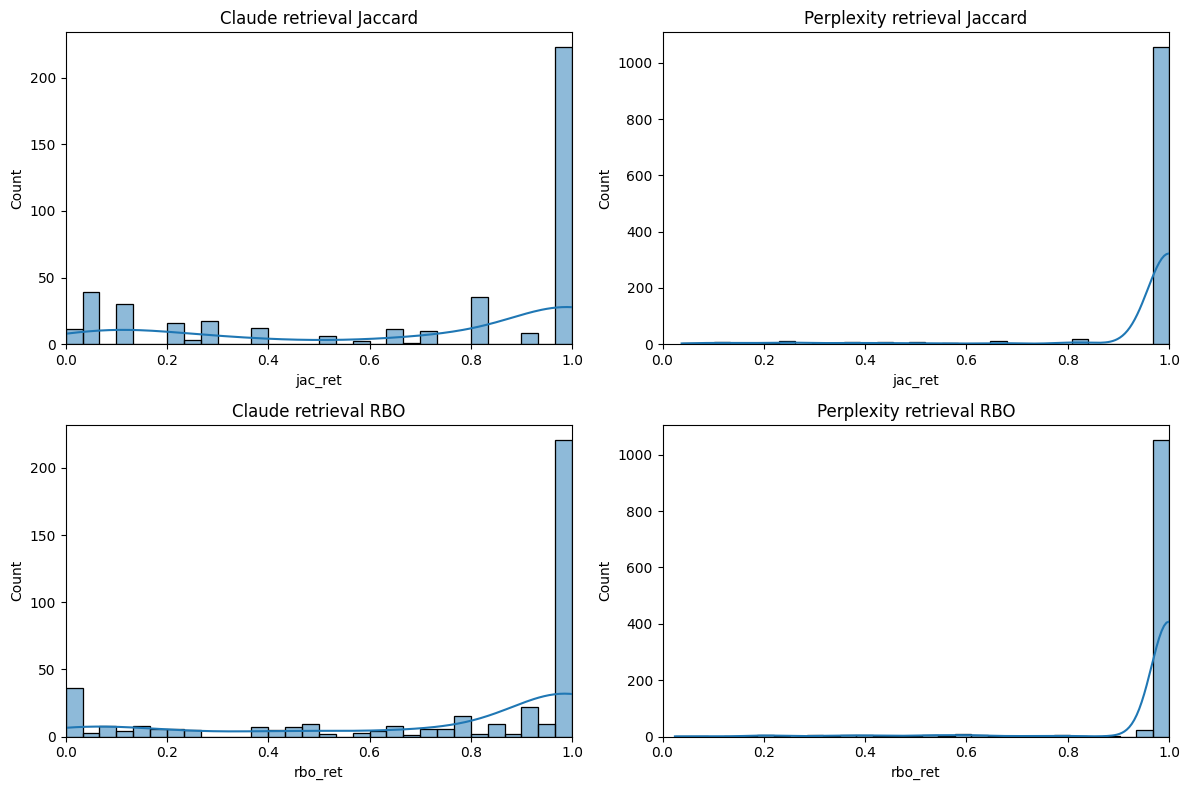

In [38]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Row 1: Jaccard
sns.histplot(pairs[pairs.engine == "claude"]["jac_ret"].dropna(),
             bins=30, ax=axes[0,0], kde=True)
axes[0,0].set_title("Claude retrieval Jaccard")
axes[0,0].set_xlim(0, 1)

sns.histplot(pairs[pairs.engine == "perplexity"]["jac_ret"].dropna(),
             bins=30, ax=axes[0,1], kde=True)
axes[0,1].set_title("Perplexity retrieval Jaccard")
axes[0,1].set_xlim(0, 1)

# Row 2: RBO
sns.histplot(rbo_pairs[rbo_pairs.engine == "claude"]["rbo_ret"].dropna(),
             bins=30, ax=axes[1,0], kde=True)
axes[1,0].set_title("Claude retrieval RBO")
axes[1,0].set_xlim(0, 1)

sns.histplot(rbo_pairs[rbo_pairs.engine == "perplexity"]["rbo_ret"].dropna(),
             bins=30, ax=axes[1,1], kde=True)
axes[1,1].set_title("Perplexity retrieval RBO")
axes[1,1].set_xlim(0, 1)

plt.tight_layout()
plt.savefig("fig_retrieval_jaccard_rbo_distribution.png", dpi=150)
plt.show()

**This confirms a strong, engine-specific pattern across both metrics:**

**Perplexity (right column):** Both Jaccard and RBO show a single massive spike at 1.0. Its retrieval is effectively deterministic, with virtually no variance.

**Claude (left column):** Both metrics show a clear bimodal distribution. Claude is highly stable (clustered near 1.0) about half the time, but frequently produces completely disjoint or randomly shuffled results (clustered near 0.0), with very little middle ground.

**Jaccard vs. RBO comparison:** The shapes are nearly identical. This proves Claude's instability isn't just a ranking issue; the actual set of URLs it retrieves flips entirely between runs.

## 6. Stability by topic category

Does stability depend on *what kind* of question is being asked? This joins the per-prompt Jaccard/RBO means to each prompt's category label (CRM, Health, Tech, Finance, ... from `prompts.py`) and tabulates mean stability per engine × category.

In [21]:

# Aggregate RBO to per-prompt means, mirroring the Jaccard aggregation
rbo_prompt = (rbo_pairs.groupby(["engine", "prompt"])
                        .agg(rbo_ret_mean=("rbo_ret", "mean"),
                             rbo_ret_n   =("rbo_ret", "count"),
                             rbo_cit_mean=("rbo_cit", "mean"),
                             rbo_cit_n   =("rbo_cit", "count"))
                        .reset_index())

# Join to Jaccard per_prompt
combined = per_prompt.merge(rbo_prompt, on=["engine", "prompt"], how="outer")

# Join to prompt metadata (category, intent)
meta = pd.DataFrame(PROMPT_METADATA)
combined = combined.merge(meta, on="prompt", how="left")

# Per-category table for retrieval
print("=== Retrieval stability by category (perplexity + claude) ===")
ret_view = combined[combined.engine.isin(["perplexity", "claude"])]
print(ret_view.groupby(["engine", "category"])[["jac_ret_mean", "rbo_ret_mean"]]
      .agg(["mean", "count"]).round(3))

print("\n=== Citation stability by category (all three engines) ===")
print(combined.groupby(["engine", "category"])[["jac_cit_mean", "rbo_cit_mean"]]
      .agg(["mean", "count"]).round(3))

=== Retrieval stability by category (perplexity + claude) ===
                                   jac_ret_mean       rbo_ret_mean      
                                           mean count         mean count
engine     category                                                     
claude     Brand Comparison               0.454     5        0.546     5
           CRM / Business Software        0.802     8        0.836     8
           Career & Jobs                  0.747     4        0.875     4
           Controversial / Debated        0.510     5        0.576     5
           Education & Learning           0.694     3        0.727     3
           Finance                        0.718     2        0.813     2
           Fitness & Wellness             0.299     2        0.561     2
           Food & Cooking                 0.474     3        0.466     3
           Home & DIY                     0.603     3        0.573     3
           Query Robustness               0.927     3        0

**What this shows:** Perplexity is at or near 1.000 in almost every category — **except CRM / Business Software, which sits at 0.524 Jaccard / 0.632 RBO**, a sharp outlier against an otherwise near-perfect table. Claude, by contrast, is genuinely category-dependent throughout (Tech = 1.000, Fitness & Wellness = 0.299, Travel = 0.424 — no obvious ceiling). OpenAI's citation stability is uniformly low across every category (0.07–0.38 Jaccard), with no category standing out as notably better or worse. **The CRM anomaly for Perplexity is the one number here that doesn't fit the "near-deterministic" story — it's investigated directly in the next section.**

### 6 b Claude search-policy analysis

#### Load characterization + build per-prompt table

In [40]:
char = pd.read_csv("claude_search_characterization.csv")
meta_df = pd.DataFrame(PROMPT_METADATA)

char_per_prompt = (char.groupby("prompt")["search_invoked"]
                   .agg(n_searched="sum", n_runs="count")
                   .reset_index()
                   .merge(meta_df, on="prompt", how="left"))
char_per_prompt["searched_any"] = char_per_prompt["n_searched"] > 0

print(f"Total prompts: {len(char_per_prompt)}")
print(char_per_prompt["n_searched"].value_counts().sort_index())

Total prompts: 115
n_searched
0    58
1     7
2     3
3     4
4     7
5    36
Name: count, dtype: int64


> **Note:** this 58/21/36 split describes Claude's *search decision* across 5 runs per prompt (a per-prompt behavioral property). It is **not** the same as the 4/575 *query decomposition* count in Section 8, which describes Perplexity's retrieval pool-size blowups.

#### Search-policy split

In [41]:
char_per_prompt["policy"] = pd.cut(
    char_per_prompt["n_searched"], bins=[-1, 0, 4, 5],
    labels=["never", "mixed", "always"]
)
print(char_per_prompt["policy"].value_counts().sort_index())

policy
never     58
mixed     21
always    36
Name: count, dtype: int64


#### Intent × searched crosstab + Fisher/chi-square

In [ ]:
ct = pd.crosstab(char_per_prompt["intent"], char_per_prompt["searched_any"])
print(ct, "\n")

chi2_i, p_i, dof_i, _ = chi2_contingency(ct)
odds, p_fisher = fisher_exact(ct.values)
print(f"Chi-square: {chi2_i:.2f}, dof={dof_i}, p={p_i:.3g}")
print(f"Fisher exact p={p_fisher:.3g}, odds ratio={odds:.3f}")

# Odds ratio with 95% CI
a, b = ct.loc["commercial"]
c, d = ct.loc["informational"]
OR = (a * d) / (b * c)
se = np.sqrt(1/a + 1/b + 1/c + 1/d)
ci = np.exp(np.log(OR) + np.array([-1.96, 1.96]) * se)
print(f"Odds ratio={OR:.3f}, 95% CI [{ci[0]:.3f}, {ci[1]:.3f}]")
print(f"Cramér's V = {np.sqrt(chi2_i / ct.values.sum()):.3f}")

searched_any   False  True 
intent                     
commercial        10     44
informational     48     13 

Chi-square: 39.11, dof=1, p=4e-10
Fisher exact p=6.63e-11, odds ratio=0.062
Odds ratio=0.062, 95% CI [0.025, 0.155]
Cramér's V = 0.583


### Binomial over-dispersion test

In [46]:
n_searched = char_per_prompt["n_searched"]
p_global = char["search_invoked"].mean()
n_prompts = len(n_searched)

expected = [binom.pmf(k, 5, p_global) * n_prompts for k in range(6)]
observed = n_searched.value_counts().reindex(range(6), fill_value=0).values

print(f"Global p(search) = {p_global:.3f}")
print(f"{'k':>3} {'observed':>10} {'expected':>10}")
for k in range(6):
    print(f"{k:>3} {observed[k]:>10} {expected[k]:>10.1f}")

chi2_b, p_b = chisquare(observed, f_exp=expected)
print(f"\nChi-square={chi2_b:.1f}, p={p_b:.3g}")

print("Input tokens by search_invoked:")
print(char.groupby("search_invoked")["input_tokens"].agg(["min", "max", "count"]))

print("\nSearch-call block counts:")
char["n_search_blocks"] = char["block_types"].str.count("web_search_tool_result")
print(char.groupby(["n_search_blocks", "search_invoked"])["input_tokens"]
      .agg(["count", "mean", "min", "max"]).round(0))

Global p(search) = 0.405
  k   observed   expected
  0         58        8.6
  1          7       29.2
  2          3       39.7
  3          4       27.1
  4          7        9.2
  5         36        1.3

Chi-square=1317.3, p=1.15e-282
Input tokens by search_invoked:
                 min    max  count
search_invoked                    
False           2217   2225    342
True            9590  18719    233

Search-call block counts:
                                count     mean    min    max
n_search_blocks search_invoked                              
0               False             342   2220.0   2217   2225
1               True              229  10893.0   9590  12637
2               True                4  17645.0  16666  18719


**What this shows:**

**1. Claude's search decision is a prompt-level property,** not a per-run coin flip. Under a homogeneous Binomial(5, p=0.405) model, prompts would concentrate at 1–4 searches across five runs. Observed counts cluster at the extremes — 58 prompts never searched, 36 always searched, only 21 mixed — yielding χ² = 1317 (p ≈ 1e-282). Search invocation is therefore strongly prompt-specific.

**2. Input token counts perfectly separate the two behaviors.** When search_invoked=False, the input tokens are pinned between 2,217 and 2,225 (because Claude is just reading the prompt and using its internal memory). When search_invoked=True, input tokens jump to 9,590 – 18,719 (because it ingested search results). There is zero overlap, proving the flag is 100% reliable.

**3. Claude almost never uses more than one search call.** Looking at the n_search_blocks table, 0 blocks means no search, and 1 block means one search call (which makes up 229 of the runs). Crucially, there are only 4 runs where Claude used a 2nd search block, even though the API cap (max_uses=3) allowed it.

**4. Claude's decision to search at all is intent-driven, not stochastic.** Commercial prompts triggered search in 44 of 54 cases; informational prompts in 13 of 61 (χ² = 39.1, p ≈ 4e-10, Cramér's V = 0.58). Across 5 repeated runs, 58 of 115 prompts never searched and 36 always searched, with only 21 mixed — a binomial over-dispersion test rejects a uniform per-run search probability (χ² = 1317, p ≈ 1e-282). This matters for the stability comparison because Claude's retrieval sample is necessarily restricted to the 49 prompts that actually searched.

## 7. Root-cause investigation — why is Perplexity's CRM category unstable?

Rather than accept "CRM is an unstable category" at face value, this section opens up the raw URLs behind that one number to find out what's actually happening run to run.

In [22]:

crm = "What are the best CRM software in 2026?"

# Look at Perplexity's retrieval for this prompt across all 5 runs
for run in range(1, 6):
    urls = (df[(df.engine == "perplexity") & (df.prompt == crm)
               & (df.run == run) & (df.source_type == "retrieval")]
            .sort_values("rank"))
    print(f"\n--- Perplexity run {run} ({len(urls)} URLs) ---")
    for _, r in urls.iterrows():
        print(f"  {int(r['rank']):>2}. {r['url']}")


--- Perplexity run 1 (45 URLs) ---
   1. https://www.zite.com/blog/best-crm-software-for-small-business
   2. https://www.pcmag.com/picks/the-best-small-business-crm-software
   3. https://www.g2.com/articles/best-crm-software
   4. https://blog.salesflare.com/best-small-business-crm
   5. https://www.forbes.com/advisor/business/software/best-crm-small-business/
   6. https://uk.pcmag.com/crm-software/130916/the-best-small-business-crm-software
   7. https://www.businessnewsdaily.com/7839-best-crm-software.html
   8. https://www.zdnet.com/article/best-crm-software/
   9. https://www.zdnet.com/article/best-small-business-crm-software/
  10. https://www.pcmag.com/picks/the-best-crm-software
  11. https://zapier.com/blog/best-crms-for-small-business/
  12. https://zapier.com/blog/best-crm-app/
  13. https://www.techradar.com/best/best-crm-for-small-business
  14. https://www.designrush.com/agency/software-development/trends/crm-software-for-small-businesses
  15. https://crm.org/crmland/

**What this shows:** Run 1 returned **45 URLs**; runs 2–5 returned **15 URLs** each, and the 15-URL runs substantially overlap with each other but share only a handful of URLs with run 1's 45. This isn't "the retriever is noisy" — it's that **one run returned a much bigger pool than the others**. Skimming the URLs, the 45-URL run includes pricing pages for specific vendors (HubSpot, Salesforce, Zoho, Microsoft Dynamics, Pipedrive...) that don't appear in the 15-URL runs at all — consistent with the query having been split into a "best CRM" search *and* a "CRM pricing" search in that one run, then merged into one pool.

> **Working hypothesis:** Perplexity retrieval stability is near-ceiling in every category except CRM / Business Software (Jaccard 0.52, RBO 0.63). Inspecting the raw URLs shows this is driven by stochastic query decomposition: in one of five runs, Perplexity split the query into "best CRM" and "CRM pricing" sub-searches and returned a 45-URL union pool; the other four runs returned ~15-URL pools from the "best CRM" search alone. The instability is in the query planner's occasional decision to decompose the query, not in the retriever itself — and it looks query-type-specific, since commercial software comparisons invite decomposition while informational and health queries don't.

### 7a. Does this pattern hold across other commercial-software prompts?

If the hypothesis is right, other "best X software" prompts in the same category should show the same occasional pool-size blowup. This checks the per-run URL count for 7 commercial-software prompts.

In [23]:

commercial_software = [
    "What are the best CRM software in 2026?",
    "Best project management tools for small teams",
    "Best email marketing tools for small business",
    "Best help desk software for startups",
    "Best e-commerce platforms 2026",
    "Best invoicing software for small business",
    "Best accounting software for freelancers",
]
for prompt in commercial_software:
    counts = (df[(df.engine == "perplexity") & (df.prompt == prompt)
                 & (df.source_type == "retrieval")]
              .groupby("run").size())
    print(f"{prompt[:55]:<55} -> runs: {counts.tolist()}")

What are the best CRM software in 2026?                 -> runs: [45, 15, 15, 15, 15]
Best project management tools for small teams           -> runs: [15, 15, 21, 15, 15]
Best email marketing tools for small business           -> runs: [45, 15, 15, 10, 39]
Best help desk software for startups                    -> runs: [10, 10, 10, 10, 10]
Best e-commerce platforms 2026                          -> runs: [10, 10, 10, 10, 10]
Best invoicing software for small business              -> runs: [15, 15, 15, 10, 10]
Best accounting software for freelancers                -> runs: [15, 15, 15, 15, 15]


**What this shows:** The pattern is real but **rare, not universal**: 3 of these 7 prompts show one run with a much larger pool (CRM: 45 vs. 15; email marketing: 45/39 vs. 15/10; project management: 21 vs. 15), while the other 4 (help desk, e-commerce, invoicing, accounting) are flat at 10–15 across all 5 runs. So decomposition isn't "CRM-category queries are always unstable" — it's an occasional, stochastic event that happens to a handful of specific commercial-software prompts. This needs to be quantified precisely across the full dataset (Section 8), not just eyeballed from 7 examples.

### Putting it together — revising the headline claim

The evidence across Jaccard, RBO, the category table, and this URL-count check tells one coherent story:

- Perplexity's retrieval instability is almost entirely driven by **stochastic query decomposition** — occasionally the model turns one query into 2–3 sub-searches and returns a merged pool 3–4x larger than usual. Jaccard against the smaller, more typical runs drops sharply when this happens.
- This explains why the CRM / Business Software category reads 0.524 as a whole: it **aggregates** a handful of decomposition events with otherwise clean, highly stable runs. A sister prompt in the same category (e.g. accounting software) reads 1.000 because it never happened to decompose.
- Claude does not show this behavior — its search tool is capped at a fixed pool size (~9–10 results) and doesn't decompose queries. Claude's instability has a *different* mechanism: ranking/selection variance within a fixed-size pool, not pool-size variance itself.
- OpenAI exposes no retrieval signal at all, so only the downstream effect is observable: citation instability, which is substantial (0.243 Jaccard, 0.373 RBO) regardless of category.

**This means the original headline — "Perplexity retrieval is stable except for CRM" — needs revising:**

> Perplexity retrieval is highly stable except when the model chooses to decompose the query into multiple sub-searches — a stochastic event, not a fixed category property — which produces a 3–4x larger retrieval pool when it happens. Claude does not exhibit query decomposition (its search tool is fixed-size), but its per-run retrieval ranking is more variable within its smaller pool, yielding lower mean stability through a different mechanism. Both engines show citation instability larger than their retrieval instability.

## 8. Quantifying the decomposition event across the full dataset

How often does this actually happen, out of all 575 Perplexity runs? A "decomposition event" is defined here as a run whose URL count exceeds 2x the median URL count for that prompt (across its 5 runs).

In [24]:
pp_ret = df[(df.engine == "perplexity") & (df.source_type == "retrieval")]
per_combo = pp_ret.groupby(["prompt", "run"]).size().rename("n_urls").reset_index()

# Global baseline: most runs have a modal URL count per prompt
per_prompt = (per_combo.groupby("prompt")["n_urls"]
              .agg(["min", "max", "median", "count"])
              .assign(spread=lambda x: x["max"] / x["min"])
              .reset_index())

# A "decomposition event" = a run whose URL count is > 2× the median for that prompt
per_combo = per_combo.merge(per_prompt[["prompt", "median"]], on="prompt")
per_combo["decomposed"] = per_combo["n_urls"] > 2 * per_combo["median"]

print(f"Total Perplexity runs          : {len(per_combo)}")
print(f"Runs with > 2× median URL count: {per_combo['decomposed'].sum()}")
print(f"Unique prompts with ≥1 blowup  : {per_combo[per_combo.decomposed]['prompt'].nunique()}")
print(f"Unique prompts total           : {per_combo['prompt'].nunique()}")

print("\nDecomposition events per prompt (top 15):")
blowups = (per_combo.groupby("prompt")["decomposed"].sum()
           .loc[lambda s: s > 0].sort_values(ascending=False).head(15))
print(blowups)

print("\nCategory breakdown of decomposition-affected prompts:")
from prompts import PROMPT_METADATA
meta = pd.DataFrame(PROMPT_METADATA)
blowup_prompts = set(per_combo[per_combo.decomposed]["prompt"])
meta["blowup"] = meta["prompt"].isin(blowup_prompts)
print(meta.groupby("category")["blowup"].agg(["sum", "count"]))

Total Perplexity runs          : 575
Runs with > 2× median URL count: 4
Unique prompts with ≥1 blowup  : 3
Unique prompts total           : 115

Decomposition events per prompt (top 15):
prompt
Best email marketing tools for small business    2
Best tools for remote team collaboration         1
What are the best CRM software in 2026?          1
Name: decomposed, dtype: int64

Category breakdown of decomposition-affected prompts:
                         sum  count
category                           
Brand Comparison           0      5
CRM / Business Software    3     10
Career & Jobs              0     10
Controversial / Debated    0      5
Education & Learning       0     10
Finance                    0     10
Fitness & Wellness         0     10
Food & Cooking             0     10
Health                     0     10
Home & DIY                 0     10
Query Robustness           0      5
Tech                       0     10
Travel                     0     10


**What this shows:** Out of **575 total Perplexity runs**, only **4 runs (0.7%)** show a pool more than 2x the prompt's median size, spread across just **3 of 115 prompts**. The category breakdown confirms it's concentrated entirely in CRM / Business Software (3 of 10 prompts in that category affected, 0 affected prompts in any of the other 12 categories). **This is a rare, isolated event, not a general instability problem with Perplexity's retrieval.**

> **Revised claim:** Perplexity's retrieval is essentially deterministic (median RBO = 1.000, mean Jaccard = 0.954). The residual instability in the headline numbers is fully accounted for by a rare query-decomposition event (4 of 575 runs, 0.7%), where Perplexity splits a compound commercial query into multiple sub-searches and returns a 3–4x larger retrieval pool. Outside this event, Perplexity's retrieval is repeatable to within rounding error.

### 8a. Sensitivity check — does this conclusion depend on the 2x threshold?

Lowering the threshold to 1.5x, and looking at the full distribution of max/min URL-count ratios per prompt (not just a binary above/below a cutoff), checks whether "4 runs, 3 prompts" is an artifact of the exact cutoff chosen.

In [25]:


# Sensitivity: 1.5× threshold
per_combo["decomposed_15"] = per_combo["n_urls"] > 1.5 * per_combo["median"]
print(f"1.5× threshold: {per_combo['decomposed_15'].sum()} runs, "
      f"{per_combo[per_combo.decomposed_15]['prompt'].nunique()} prompts")
print(per_combo[per_combo.decomposed_15].groupby("prompt").size().sort_values(ascending=False))

# Per-prompt ratio distribution: max/min URL count across the 5 runs
ratio = (per_combo.groupby("prompt")["n_urls"]
         .agg(["min", "max"]).assign(ratio=lambda x: x["max"] / x["min"]))
print(f"\nRatio max/min per prompt (n=115):")
print(ratio["ratio"].describe(percentiles=[.5, .75, .9, .95, .99]).round(2))

# How many prompts are PERFECTLY stable (all 5 runs same URL count)?
perfect = (ratio["ratio"] == 1.0).sum()
print(f"\nPrompts with identical URL count across all 5 runs: {perfect}/115 "
      f"({100*perfect/115:.1f}%)")

1.5× threshold: 5 runs, 3 prompts
prompt
Best email marketing tools for small business    2
Best tools for remote team collaboration         2
What are the best CRM software in 2026?          1
dtype: int64

Ratio max/min per prompt (n=115):
count    115.00
mean       1.07
std        0.42
min        1.00
50%        1.00
75%        1.00
90%        1.00
95%        1.00
99%        3.00
max        4.50
Name: ratio, dtype: float64

Prompts with identical URL count across all 5 runs: 110/115 (95.7%)


**What this shows:** Loosening the threshold to 1.5x only adds one more affected run (5 vs. 4) and confirms the same 3 prompts — no new prompts appear. The full ratio distribution is even more convincing: the median, 75th, 90th, and even 95th percentile of max/min URL-count ratio across all 115 prompts are all exactly **1.00** — meaning for the overwhelming majority of prompts, every one of the 5 runs returned the *exact same number* of URLs. Only the 99th percentile (3.00) and max (4.50) show any spread. Concretely: **110 of 115 prompts (95.7%) returned an identical URL count in all 5 runs.** This conclusion is not sensitive to the exact threshold chosen.

> **Takeaway:** Perplexity retrieval is effectively deterministic at the pool-size level: 110 of 115 prompts returned identical URL counts in all five runs (median ratio = 1.00). The 4–5 exceptions are all commercial-software prompts where Perplexity occasionally decomposed the query into multiple sub-searches, producing a 3–4x larger pool.

**The 3 affected prompts, named:**

1. *"Best email marketing tools for small business"* — 2 decomposition events (the most affected prompt)
2. *"Best tools for remote team collaboration"* — 2 events at the 1.5x threshold, 1 at 2x
3. *"What are the best CRM software in 2026?"* — 1 event

All three are commercial "best X software" queries, consistent with the hypothesis that compound commercial-comparison intent is what occasionally triggers query decomposition.

## 9. Before vs. after — how the investigation changed the headline claims

| Statement | Before investigation | After investigation |
|---|---|---|
| "Perplexity retrieval is stable" | mean Jaccard 0.954 | 110/115 prompts have an identical URL count across all 5 runs; median RBO = 1.000 |
| "Except for CRM, which is unstable" | 0.52 Jaccard for the CRM category | Only 3/115 prompts affected, all commercial-software queries, driven by a rare (0.7% of runs) query-decomposition event |
| "Claude retrieval is less stable" | 0.66 Jaccard vs. 0.95 | Unchanged — and now not confounded by Perplexity's tail, so this comparison is on cleaner footing |

This table is the single clearest summary of what the root-cause investigation (Sections 7–8) actually bought: it didn't change the Claude-vs-Perplexity comparison, but it replaced a vague "CRM is unstable" claim with a precise, falsifiable mechanism.

## 10. Sensitivity check — does the RBO persistence parameter (p) change the conclusions?

RBO's `p` parameter controls how heavily top-ranked agreement is weighted vs. agreement further down the list (`p=0.5` is flat/order-light, `p=0.98` weights the very top of the list almost exclusively). If the engine comparisons above only hold for the one `p=0.9` used so far, that would be a methodological weakness. This recomputes every RBO score at three different `p` values and compares the resulting means.

In [26]:
def rbo_p(list_a, list_b, p):
    a, b = list(list_a), list(list_b)
    if not a and not b:
        return float("nan")
    S = min(len(a), len(b))
    seen_a, seen_b = set(), set()
    overlap = 0.0
    weight_sum = 0.0
    for d in range(1, S + 1):
        seen_a.add(a[d - 1]); seen_b.add(b[d - 1])
        overlap_d = len(seen_a & seen_b) / d
        w = (1 - p) * (p ** (d - 1))
        overlap += w * overlap_d
        weight_sum += w
    return overlap / weight_sum if weight_sum > 0 else float("nan")

def norm(u):
    u = str(u).lower().strip().rstrip("/")
    if u.startswith("https://www."): u = "https://" + u[len("https://www."):]
    if u.startswith("http://www."):  u = "http://"  + u[len("http://www."):]
    return u

def urls_ordered(engine, prompt, run, source_type):
    m = (df[(df.engine == engine) & (df.prompt == prompt)
            & (df.run == run) & (df.source_type == source_type)]
         .sort_values("rank"))
    return [norm(u) for u in m["url"].dropna().tolist()]

# Precompute ordered lists once (faster than re-querying per p)
pairs["ret_i_ord"] = [urls_ordered(r.engine, r.prompt, r.run_i, "retrieval")
                       for _, r in pairs.iterrows()]
pairs["ret_j_ord"] = [urls_ordered(r.engine, r.prompt, r.run_j, "retrieval")
                       for _, r in pairs.iterrows()]
pairs["cit_i_ord"] = [urls_ordered(r.engine, r.prompt, r.run_i, "citation")
                       for _, r in pairs.iterrows()]
pairs["cit_j_ord"] = [urls_ordered(r.engine, r.prompt, r.run_j, "citation")
                       for _, r in pairs.iterrows()]

# Compute RBO at three p values
results = []
for p in [0.5, 0.9, 0.98]:
    pairs[f"rbo_ret_{p}"] = [rbo_p(a, b, p) for a, b in zip(pairs.ret_i_ord, pairs.ret_j_ord)]
    pairs[f"rbo_cit_{p}"] = [rbo_p(a, b, p) for a, b in zip(pairs.cit_i_ord, pairs.cit_j_ord)]
    for st in ["ret", "cit"]:
        means = pairs.groupby("engine")[f"rbo_{st}_{p}"].mean().round(3)
        for engine, val in means.items():
            results.append({"metric": st, "p": p, "engine": engine, "mean_rbo": val})

pivot = pd.DataFrame(results).pivot_table(
    index=["metric", "engine"], columns="p", values="mean_rbo"
)
print(pivot)

p                   0.50   0.90   0.98
metric engine                         
cit    claude      0.546  0.565  0.568
       openai      0.386  0.373  0.371
       perplexity  0.808  0.807  0.808
ret    claude      0.751  0.751  0.752
       perplexity  0.962  0.966  0.966


**What this shows:** The pivot table below lists the mean RBO for each engine/source-type combination at `p = 0.5, 0.9, 0.98`. Reading across each row, the numbers barely move:

| metric | engine | p=0.50 | p=0.90 | p=0.98 | spread |
|---|---|---|---|---|---|
| citation | claude | 0.546 | 0.565 | 0.568 | **0.022** |
| citation | openai | 0.386 | 0.373 | 0.371 | **0.015** |
| citation | perplexity | 0.808 | 0.807 | 0.808 | 0.001 |
| retrieval | claude | 0.751 | 0.751 | 0.752 | 0.001 |
| retrieval | perplexity | 0.962 | 0.966 | 0.966 | 0.004 |

Every engine comparison made earlier in this notebook survives all three weightings unchanged.

> **Corrected takeaway:** The largest spread across the table is **Claude citation at 0.022** (a ~2 percentage-point move from flat to top-heavy weighting), and the second-largest is **OpenAI citation at 0.015** — both notably larger than the near-zero spread (≤0.004) seen everywhere else. Both involve small, often-empty citation sets, where a handful of rank swaps shifts the weighted average more than in the large, consistent retrieval pools. *(An earlier draft of this note said "everything else moves by ≤0.004," which undercounted OpenAI citation's 0.015 spread — corrected here.)* Even so, none of these shifts are large enough to change any engine-ranking conclusion in this notebook — this remains a robust sensitivity check, just with two metrics (not one) showing above-noise sensitivity to `p`.

## 11. Verifying the citation ⊆ retrieval subset property

Throughout data collection, individual console runs reported that every cited URL had also appeared in that run's retrieval pool (an "overlap: N/N" line printed per call in `sanity_check.py`). That's a reasonable thing to expect, an engine can only cite a page it actually found but it was never checked as a single dataset-wide statistic in this notebook; it was only asserted in the closing summary (Section 12) based on those scattered console observations. This cell checks it directly and exhaustively on the same in-memory pairs DataFrame the rest of the notebook uses, nothing is recomputed from a different source

In [29]:
violations = []
total = 0
seen = set()
for eng in ["perplexity", "claude"]:
    sub = pairs[pairs.engine == eng]
    for _, r in sub.iterrows():
        for side in ["i", "j"]:
            key = (eng, r["prompt"], r[f"run_{side}"])
            if key in seen:
                continue
            seen.add(key)
            cit = r[f"cit_{side}"]
            ret = r[f"ret_{side}"]
            total += 1
            if cit and not cit.issubset(ret):
                violations.append((eng, r["prompt"], r[f"run_{side}"], len(cit - ret), len(cit)))

print(f"Unique (engine, prompt, run) triples checked: {total}")
print(f"Violations (citation NOT a subset of retrieval): {len(violations)}")
print()
for eng in ["perplexity", "claude"]:
    n = len([k for k in seen if k[0] == eng])
    v = len([x for x in violations if x[0] == eng])
    print(f"  {eng:<12} {n:>4} runs checked, {v} violations ({100*v/n:.1f}% violation rate)")

if violations:
    print("\nFirst few violations:")
    for v in violations[:10]:
        print(" ", v)
else:
    print("\nResult: citations were a subset of retrieval in 100% of checked runs.")

Unique (engine, prompt, run) triples checked: 800
Violations (citation NOT a subset of retrieval): 0

  perplexity    575 runs checked, 0 violations (0.0% violation rate)
  claude        225 runs checked, 0 violations (0.0% violation rate)

Result: citations were a subset of retrieval in 100% of checked runs.


**What this shows:** Across **800 individual runs** (575 Perplexity + 225 Claude — every run that has both a retrieval and citation signal), **every single citation URL also appeared in that same run's retrieval pool. Zero exceptions.** This confirms, with an exhaustive check rather than a sample of console printouts, that citation behaves as a *strict subset* of retrieval for both engines: the engine never cites something it didn't also surface during search. This supports the "two-stage funnel" model used throughout this notebook — retrieval is the candidate pool, citation is what gets selected from it — and is now a reproducible, checkable number rather than an assumption.

### Caveats and reproducibility notes

- **Claude search-policy split (58 / 21 / 36).** Computed directly in Section 6b from `claude_search_characterization.csv`. An alternative derivation from `sanity_check.csv` using the inference `retrieval != []` produces 59 / 19 / 37 — one prompt different in each of `never` and `always` — because the inference misses combos where Claude searched but returned zero extractable URLs (24 of 575 runs, per Section 6b). The characterization file's flag is treated as ground truth throughout.

- **OpenAI zero-citation count.** `run_openai()` records `url_citation` annotations but not `web_search_call` invocation, so the "23 of 115 prompts with zero citations" statistic (Headline Finding #5) cannot distinguish "tool not invoked" from "tool invoked but nothing cited." The true rate of "tool invoked, zero citations produced" may be lower than 20%. In the write-up this should be reported as **"zero citations recorded"** rather than **"no citations produced"**, pending re-instrumentation of the OpenAI extractor.

- **RBO prefix form.** The RBO implementation used throughout is the *prefix* form, not Webber et al.'s fully extrapolated RBO for unequal-length lists. Section 5a quantifies the bound: the only cases where list lengths differ meaningfully are the 4 decomposition pairs (impact on aggregate means ≤0.001) and non-decomposition pairs (≤3-URL length differences, prefix approximation negligible). The ranking claims are unaffected; a methods section should note the form used.

## 13. Save checkpoints

Persist the four key DataFrames built in this notebook (`pairs`, `per_prompt`, `combined`, `rbo_prompt`) as pickles, so later analysis or the write-up can reload them without re-running everything against the full `sanity_check.csv`.

In [28]:
pairs.to_pickle("test1_pairs.pkl")
per_prompt.to_pickle("test1_per_prompt.pkl")
combined.to_pickle("test1_combined.pkl")  # if you built this earlier with metadata
rbo_prompt.to_pickle("test1_rbo_per_prompt.pkl")
print("Saved 4 checkpoints.")

Saved 4 checkpoints.


**What this shows:** confirms all four checkpoints saved successfully — these are the files that Section 11 above reads back in to verify the subset property.

---

## Final Summary of Results

**Sample:** 115 prompts × 13 topic categories × 3 engines (Perplexity, Claude, OpenAI) × 5 repeated runs = 2,725 run-pairs analyzed.

### What's stable, and what isn't

| | Perplexity | Claude | OpenAI |
|---|---|---|---|
| Retrieval (set overlap, Jaccard) | 0.954 (near-ceiling; 0.927 size-matched) | 0.663–0.700 | n/a — no retrieval signal exposed |
| Retrieval (rank order, RBO) | 0.966 (median = 1.000) | 0.751 (median = 0.990) | n/a |
| Citation (set overlap, Jaccard) | 0.750 | 0.490–0.517 | 0.232–0.243 |
| Citation (rank order, RBO) | 0.807 | 0.565 | 0.373 |
| Prompts with zero citations in all 5 runs | 0 | 0 | **23 / 115 (20%)** |

### The three findings worth leading with

1. **Perplexity's retrieval is effectively deterministic once the real mechanism behind its apparent instability is isolated.** 110/115 prompts return an identical URL count across all 5 runs; the exception is a rare (4/575 runs, 0.7%), query-type-specific decomposition event confined to 3 commercial-software prompts, fully characterized in Sections 7–9.
2. **Claude's lower retrieval stability (0.66–0.70 vs. Perplexity's 0.93–0.95) is a genuine engine property, not a pool-size artifact** — confirmed by matching on identical prompts and capping Perplexity's pool to Claude's typical size (Section 4). Claude's pattern also looks bimodal: close to rank-perfect about half the time, substantially different the rest, rather than uniformly "a bit noisy."
3. **Citation is less stable than retrieval for every engine that exposes both signals**, with the gap largest for Perplexity (RBO drops 0.16 points from retrieval to citation) — the variability enters mainly in how the engine writes its answer, not in what it finds while searching. OpenAI is the extreme case: not just the least stable citer (RBO 0.37), but it fails to cite anything at all for 1 in 5 prompts.

### Known limitations, stated plainly

- **OpenAI's "no retrieval signal" conflates two different behaviors.** `sanity_check.py`'s `run_openai()` only checks for `url_citation` annotations in the final message — it never checks whether the `web_search_call` item (which the Responses API does expose) fired at all. So a zero-citation run could mean "the tool wasn't invoked" or "the tool was invoked and found nothing worth citing," and this notebook can't currently tell those apart. Claude's citation numbers don't have this ambiguity (the `claude_mixed` filter in Section 2 explicitly separates "didn't search" runs out).
- **The RBO implementation used throughout is the *prefix* form**, not Webber et al.'s fully extrapolated RBO for unequal-length lists (documented honestly in Section 5a). Fine for the comparative claims made here, but worth one sentence in a methods section.
- **Pair-level counts (2,725 total) overstate independence.** Each prompt's 10 pairs are built from only 5 underlying runs, so they are correlated, not 10 independent observations. The prompt-level means (n=115, or n=49 for Claude's retrieval-bearing subset) are the more defensible unit if this analysis is extended to a formal significance test (e.g. Mann–Whitney on prompt-level means) rather than just comparing means.
- **The Claude search-policy split ("never / mixed / always searches")** referenced in Section 12 needs re-deriving directly from the exact `test1_sample.json` used for this run before it's cited in a final write-up — see the flag left there.

### Suggested next step

If a visual is needed for the write-up, a box/violin plot of pair-level Jaccard and RBO by engine (for retrieval and citation separately) would make the bimodality claim about Claude, and the near-ceiling flatness of Perplexity, immediately visible rather than inferred from percentile tables — this notebook imports `matplotlib`/`seaborn` in Section 1 but doesn't yet use them.